In [1]:
import torch
from torch import nn

from tqdm.notebook import tqdm

import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import clear_output


import torchvision
import torch.nn.functional as F
from torch.optim.lr_scheduler import ExponentialLR


import gc
from collections import defaultdict
import typing as tp
import numpy as np
import copy
import pickle


In [2]:
DATASET_FOLDER = '~/projects/datasets'


train_transformations = torchvision.transforms.Compose([
    torchvision.transforms.RandomHorizontalFlip(),
    torchvision.transforms.RandomRotation((-7,7)),
    torchvision.transforms.RandomAffine(0, shear=10, scale=(0.8,1.2)),
    torchvision.transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261))
])

test_transformations = torchvision.transforms.Compose([
    torchvision.transforms.ToTensor(),
    torchvision.transforms.Normalize((0.491, 0.482, 0.446), (0.247, 0.243, 0.261))
])


cifar_train = torchvision.datasets.CIFAR10(root=DATASET_FOLDER,
                                           transform=train_transformations,
                                           download=True,
                                           train=True)


cifar_test = torchvision.datasets.CIFAR10(root=DATASET_FOLDER,
                                          transform=test_transformations,
                                          download=True,
                                          train=False)


In [3]:
class Resnet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torchvision.models.resnet34()
        self.net.fc = nn.Linear(512, 10)

    def forward(self, x):
        return self.net(x)

In [4]:
def get_list_grad_params(net: nn.Module) -> tp.List[torch.Tensor]:
    return [param.grad.detach().cpu() for param in net.parameters() if param.grad is not None]

def calc_grad_info(net: nn.Module, info: tp.List[torch.Tensor]):
    new_grads = get_list_grad_params(net)
    if not info:
        return new_grads
    return [new_grad + cur_grad for new_grad, cur_grad in zip(new_grads, info)]

def get_dif(grad_info_1: tp.List[torch.Tensor], grad_info_2: tp.List[torch.Tensor]) -> tp.List[torch.Tensor]:
    return [grad_1 - grad_2 for grad_1, grad_2 in zip(grad_info_1, grad_info_2)]

def mult_grad(info: tp.List[torch.Tensor], mult: float):
    return [grad * mult for grad in info] 

def get_grad_norm(grads: tp.List[torch.Tensor]):
    return np.sqrt(sum(grad.norm().item() ** 2 for grad in grads))


In [14]:
def plot_loss(values: defaultdict, suptitle: str):
    clear_output()
    with sns.plotting_context("notebook"), sns.axes_style("darkgrid"):
        plt.figure(figsize=(28, 6), dpi=120)

        subplots_shape = (1, 3)

        plt.suptitle(suptitle)

        plt.subplot(*subplots_shape, 1)
        train_loss = values["train_loss"]
        plt.plot(range(1, len(train_loss) + 1), train_loss)
        plt.title('Train loss')
        plt.xlabel("Iterations")

        plt.subplot(*subplots_shape, 2)
        test_accuracy = values["test_accuracy"]
        plt.plot(range(1, len(test_accuracy) + 1), test_accuracy)
        plt.title('Test accuracy')
        plt.yticks(fontsize=10)
        plt.xlabel("Epochs")

        # plt.subplot(*subplots_shape, 3)
        # error = values["alpha_16/32"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp32 $\to$ fp16')
        # plt.xlabel("Iterations")
        
        plt.subplot(*subplots_shape, 3)
        error = values["alpha_16/64"]
        plt.plot(range(1, len(error) + 1), error)
        plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp16')
        plt.xlabel("Iterations")

        # plt.subplot(*subplots_shape, 5)
        # error = values["alpha_32/64"]
        # plt.plot(range(1, len(error) + 1), error)
        # plt.title(r'$\alpha$ - relative noise coefficient fp64 $\to$ fp32')
        # plt.xlabel("Iterations")


        plt.show()

In [15]:
def train_cycle(
    model,
    optim,
    scheduler,
    criterion,
    epochs,
    device,
    train_dataloader,
    test_dataloader,
    output_suptitle,
    verbose=True,
):
    history = defaultdict(list)

    for _ in range(epochs):
        model.train()

        for x, y in tqdm(train_dataloader):
            full_grad_16 = []
            full_grad_64 = []

            optim.zero_grad()
            model_cp = copy.deepcopy(model).half()
            model_cp.train()
            x = x.to(device).type(torch.float16)
            logits = model_cp(x)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_16 = calc_grad_info(model_cp, full_grad_16)

            optim.zero_grad()
            x = x.to(device).type(torch.double)
            logits = model(x)
            y_ = y.to(device)
            loss_batch = criterion(logits, y_)
            loss_batch.backward()
            full_grad_64 = calc_grad_info(model, full_grad_64)

            history["alpha_16/64"].append(get_grad_norm(get_dif(full_grad_16, full_grad_64)) / get_grad_norm(full_grad_64))
            #history["alpha_16/32"].append(get_grad_norm(get_dif(full_grad_16, full_grad_32)) / get_grad_norm(full_grad_32))
            #history["alpha_32/64"].append(get_grad_norm(get_dif(full_grad_32, full_grad_64)) / get_grad_norm(full_grad_64))

            optim.step()
            loss_ = loss_batch.detach().item()
            history["train_loss"].append(loss_)
            del x
            del y
            del y_
            if 'cuda' in device:
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
                gc.collect()


        scheduler.step()

        model.eval()
        with torch.no_grad():
            accuracy = 0
            total = 0
            for x, y in test_dataloader:
                data, target = x.to(device).type(torch.double), y
                output = model(data)
                pred = output.argmax(dim=1, keepdim=True).T[0].cpu()
                accuracy += pred.eq(target.view_as(pred)).sum().item()
                total += len(y)
            history["test_accuracy"].append(accuracy / total)

        if verbose:
            plot_loss(history, output_suptitle)

    return model, history

In [ ]:
device = "cuda:0" if torch.cuda.is_available() else "cpu"

model = Resnet().to(device).double()

batch_size: int = 512
workers: int = 12
learning_rate = 1e-3

suptitle = 'Simple CNN, MNIST, floating point gradient quantization'

In [17]:

dataloader_train = torch.utils.data.DataLoader(cifar_train,
                                               num_workers=workers,
                                               batch_size=batch_size,
                                               sampler=torch.utils.data.RandomSampler(cifar_train))

dataloader_test = torch.utils.data.DataLoader(cifar_test,
                                              num_workers=workers,
                                              batch_size=batch_size,
                                              sampler=torch.utils.data.RandomSampler(cifar_test))


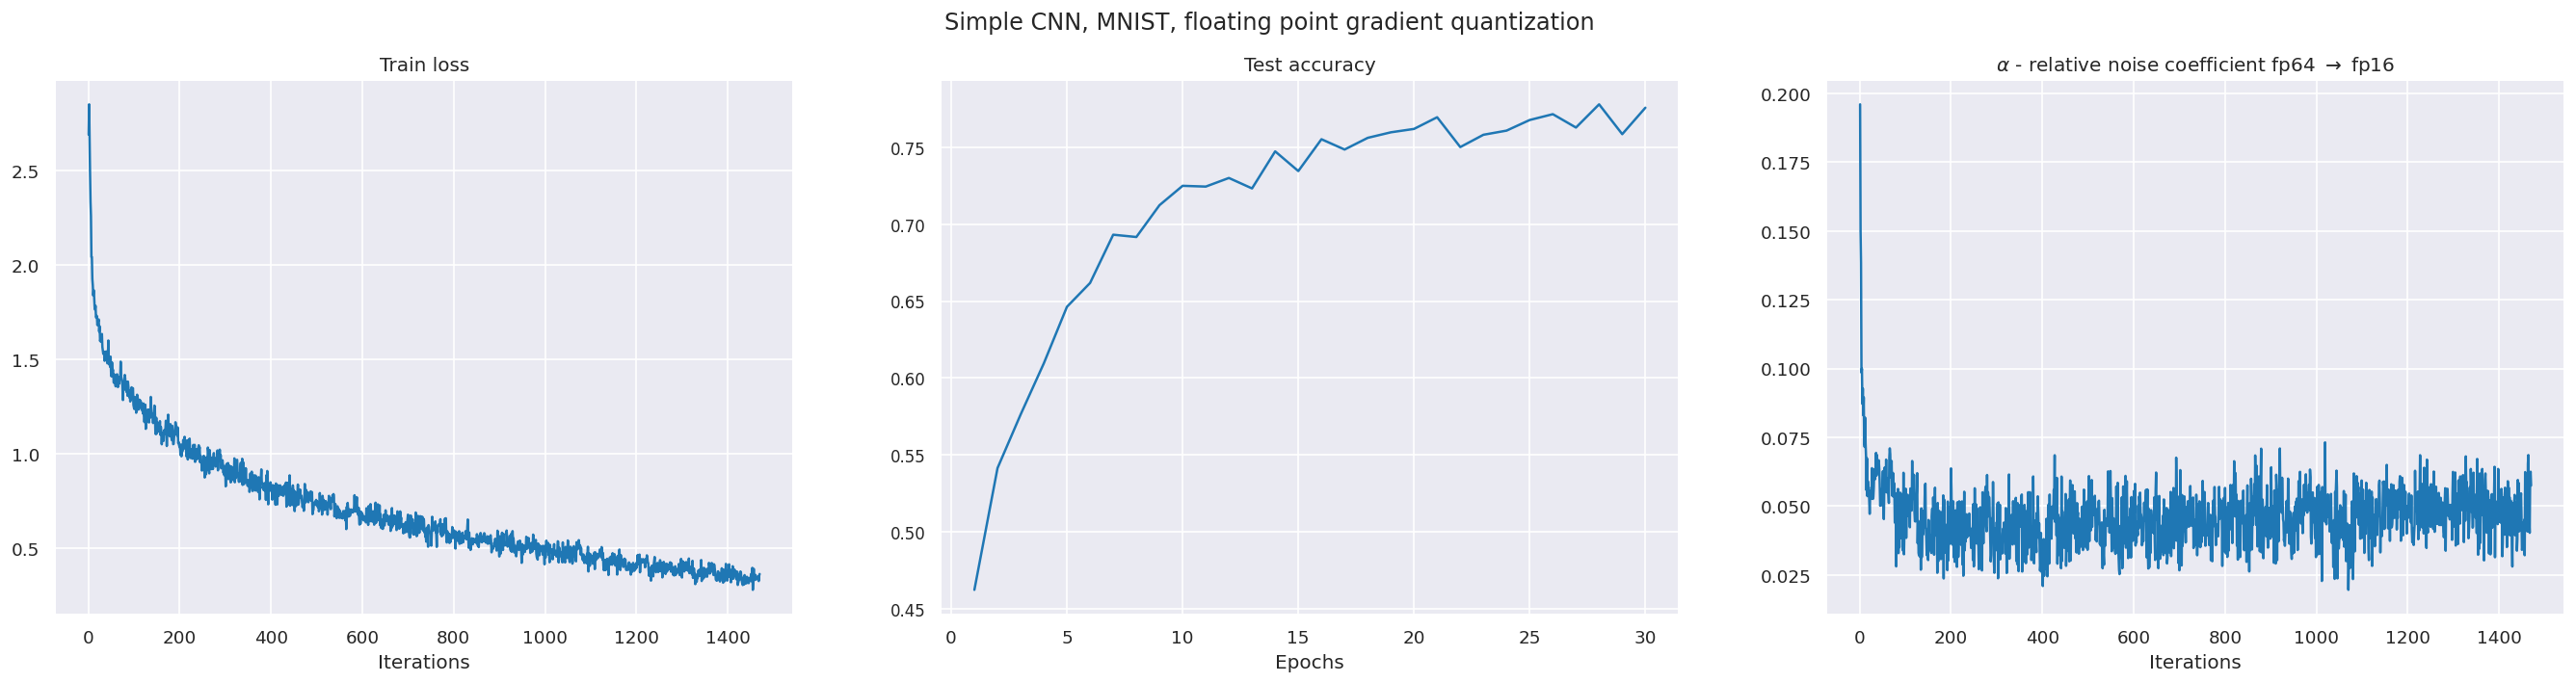

In [19]:
model = Resnet().to(device).double()

optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
scheduler = ExponentialLR(optimizer, gamma=0.95)
criterion = nn.CrossEntropyLoss()
verbose = True

epochs = 30

model, history = train_cycle(model,
                             optimizer,
                             scheduler,
                             criterion,
                             epochs,
                             device,
                             dataloader_train,
                             dataloader_test,
                             output_suptitle=suptitle,
                             verbose=True)

In [21]:
with open('./dump_result/resnet34_fp.pickle', 'wb') as f:
    pickle.dump(history, f)
